# 06 EuroBERT tokenisation and chunking

This notebook takes over from Notebook 05. It reads **original text** from `output/preprocessing/sections.jsonl`, joins the language records by document and section, tokenises the text with the actual EuroBERT tokenizer, and creates overlapping chunks that fit a chosen token budget. It documents tokenisation behaviour and checks source coverage. All code is inside this notebook.

**Tokenisation** converts text into model-specific pieces and numerical IDs. A token can be a whole word, part of a word, punctuation or whitespace. **Chunking** divides a long token sequence into smaller windows; a small overlap repeats context near the boundaries. **EuroBERT** is a multilingual encoder model that may later turn these inputs into representations. This notebook loads only tokenizer/configuration files and computes no embeddings.

The working window is **1,024 total input tokens**, with **128 content tokens of overlap**. This is an adjustable preparation choice, not EuroBERT's architectural limit or a proven optimum. The checkpoint's configuration supplies its actual 8,192-token limit. The notebook compares alternative window sizes before constructing chunks.


## 1 Setup and configuration

Run from the project root or `notebooks/`. If imports fail, run this once in a notebook cell and restart the kernel:

```python
%pip install transformers pandas matplotlib
```

The selected EuroBERT-210m tokenizer is a concrete preparation target, not a decision about the final embedding model. 

In [1]:
from pathlib import Path
from bisect import bisect_left, bisect_right
import hashlib
import json
import math
import re
import time
import platform

import pandas as pd
import matplotlib.pyplot as plt
import transformers
import tokenizers
from transformers import AutoTokenizer
from huggingface_hub import snapshot_download

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'output/preprocessing/sections.jsonl').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run from the project root or notebooks folder, with Notebook 05 exports under output/preprocessing/.')

INPUT_DIR = ROOT / 'output/preprocessing'
OUTPUT_DIR = ROOT / 'output/tokenization'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ID = 'EuroBERT/EuroBERT-210m'
MODEL_REVISION = '39b51e15dd1f1a06f58b5cbf6a8a188cec60bd0e'
TOKENIZER_DIR = ROOT / 'models' / (MODEL_ID.replace('/', '--') + '-' + MODEL_REVISION[:8])
MAX_INPUT_TOKENS = 1024
OVERLAP_TOKENS = 128
RANDOM_SEED = 42
print('Inputs:', INPUT_DIR.relative_to(ROOT))
print('Outputs:', OUTPUT_DIR.relative_to(ROOT))

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Inputs: output\preprocessing
Outputs: output\tokenization


## 2 Load and link the handover inputs

Join language metadata using `(document_id, section_number)` rather than CSV row order. A mismatch stops the notebook. The original text is retained exactly, and the experimental stop-word-filtered file is not loaded. Each source section receives a stable ID based on its existing keys and original text.

In [2]:
sections_path = INPUT_DIR / 'sections.jsonl'
languages_path = INPUT_DIR / 'section_languages.csv'
input_hashes_before = {path.name: hashlib.sha256(path.read_bytes()).hexdigest() for path in [sections_path, languages_path]}
sections = pd.read_json(sections_path, lines=True)
languages = pd.read_csv(languages_path, keep_default_na=False)
keys = ['document_id', 'section_number']
required = {'document_id', 'section_number', 'section_label', 'original_text', 'file_name', 'page_start', 'page_end'}
assert required <= set(sections.columns), 'Required source columns are missing.'
assert sections.original_text.map(lambda value: isinstance(value, str)).all(), 'Every source text must be a string.'
assert not sections.duplicated(keys).any() and not languages.duplicated(keys).any(), 'Duplicate section keys.'
joined = sections.merge(languages[keys + ['section_label', 'detected_language', 'language_score']],
                        on=keys, how='outer', validate='one_to_one', suffixes=('', '_language'), indicator=True)
assert joined['_merge'].eq('both').all(), 'Missing or extra language records.'
assert joined.section_label.equals(joined.section_label_language), 'Language labels refer to different sections.'
joined = joined.drop(columns=['section_label_language', '_merge'])
joined['source_section_id'] = joined.apply(
    lambda row: 'sec_' + hashlib.sha256(
        f"{row.document_id}:{row.section_number}:{row.original_text}".encode('utf-8')
    ).hexdigest()[:20], axis=1)
joined['source_text_sha256'] = joined.original_text.map(lambda text: hashlib.sha256(text.encode('utf-8')).hexdigest())
assert not joined.source_section_id.duplicated().any()
print('Original sections:', len(joined))
print('Documents with sections:', joined.document_id.nunique())
print('Original characters:', int(joined.original_text.str.len().sum()))
display(joined.detected_language.value_counts().rename('sections').to_frame())

Original sections: 3327
Documents with sections: 92
Original characters: 9367556


,sections
detected_language,
en,1590
nl,1542
uncertain,188
fr,5
de,2


## 3 Load the real tokenizer and establish the token budget

Use the tokenizer attached to the checkpoint; splitting text on spaces would not produce EuroBERT input IDs. Load `config.json` as data to obtain the model limit without loading model weights or running repository code.

The tokenizer's `model_max_length` can contain a very large placeholder, so it is not used as the architecture limit. Special tokens also occupy input positions. The notebook inspects the tokenizer's actual single-sequence wrapper instead of assuming BERT's CLS/SEP convention.

In [3]:
asset_names = ['tokenizer.json', 'tokenizer_config.json', 'special_tokens_map.json', 'config.json']
source_manifest = TOKENIZER_DIR / 'source_revision.json'
if not source_manifest.exists() or not all((TOKENIZER_DIR / name).is_file() for name in asset_names):
    snapshot_download(MODEL_ID, revision=MODEL_REVISION, allow_patterns=asset_names, local_dir=str(TOKENIZER_DIR))
    source_manifest.write_text(json.dumps({'model_id': MODEL_ID, 'revision': MODEL_REVISION}, indent=2))
assert json.loads(source_manifest.read_text()) == {'model_id': MODEL_ID, 'revision': MODEL_REVISION}
tokenizer = AutoTokenizer.from_pretrained(str(TOKENIZER_DIR), use_fast=True,
                                          trust_remote_code=False, local_files_only=True)
assert tokenizer.is_fast, 'A fast tokenizer is needed for character offsets.'
model_config = json.loads((TOKENIZER_DIR / 'config.json').read_text())
MODEL_LIMIT = int(model_config['max_position_embeddings'])
probe_text = 'Tokenisation inspection example.'
probe_plain = tokenizer(probe_text, add_special_tokens=False, truncation=False)['input_ids']
probe_full = tokenizer(probe_text, add_special_tokens=True, return_special_tokens_mask=True, truncation=False)
content_positions = [i for i, flag in enumerate(probe_full['special_tokens_mask']) if not flag]
PREFIX_IDS = probe_full['input_ids'][:content_positions[0]]
SUFFIX_IDS = probe_full['input_ids'][content_positions[-1] + 1:]
assert probe_full['input_ids'] == PREFIX_IDS + probe_plain + SUFFIX_IDS
SPECIAL_TOKEN_COUNT = len(PREFIX_IDS) + len(SUFFIX_IDS)
assert SPECIAL_TOKEN_COUNT == tokenizer.num_special_tokens_to_add(pair=False)
CONTENT_BUDGET = MAX_INPUT_TOKENS - SPECIAL_TOKEN_COUNT
assert 0 < MAX_INPUT_TOKENS <= MODEL_LIMIT
assert 0 <= OVERLAP_TOKENS < CONTENT_BUDGET
display(pd.DataFrame([
    {'setting': 'Tokenizer', 'value': tokenizer.__class__.__name__},
    {'setting': 'Checkpoint maximum input tokens', 'value': MODEL_LIMIT},
    {'setting': 'Chosen total input tokens per chunk', 'value': MAX_INPUT_TOKENS},
    {'setting': 'Automatically added special tokens', 'value': SPECIAL_TOKEN_COUNT},
    {'setting': 'Content-token budget per chunk', 'value': CONTENT_BUDGET},
    {'setting': 'Target content-token overlap', 'value': OVERLAP_TOKENS},
    {'setting': 'Special prefix IDs', 'value': str(PREFIX_IDS)},
    {'setting': 'Special suffix IDs', 'value': str(SUFFIX_IDS)},
]))
print('Tokenizer vocabulary size:', len(tokenizer))

,setting,value
0,Tokenizer,TokenizersBackend
1,Checkpoint maximum input tokens,8192
2,Chosen total input tokens per chunk,1024
3,Automatically added special tokens,1
4,Content-token budget per chunk,1023
5,Target content-token overlap,128
6,Special prefix IDs,[]
7,Special suffix IDs,[128001]


Tokenizer vocabulary size: 128256


## 4 Tokenise all original sections without truncation

Tokenise each whole section first, with no padding, truncation or automatically added special tokens. Store content IDs and section-relative character offsets. Decode the full content IDs and compare them with the original text; this checks the actual tokenizer's round-trip behaviour rather than assuming it is lossless.

Whitespaces and existing PDF extraction artefacts are retained. Successful tokenisation does not repair mixed columns or incorrect section labels. Keep those findings separate from failures introduced by this stage.

In [4]:
started = time.perf_counter()
token_records = []
for row in joined.to_dict(orient='records'):
    encoded = tokenizer(row['original_text'], add_special_tokens=False, truncation=False,
                        padding=False, return_offsets_mapping=True, return_attention_mask=False, verbose=False)
    ids = encoded['input_ids']
    offsets = encoded['offset_mapping']
    decoded = tokenizer.decode(ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)
    assert len(ids) == len(offsets)
    assert all(0 <= start <= end <= len(row['original_text']) for start, end in offsets)
    token_records.append({**row, 'content_input_ids': ids, 'offset_mapping': offsets,
                          'content_token_count': len(ids), 'roundtrip_exact': decoded == row['original_text'],
                          'unknown_token_count': ids.count(tokenizer.unk_token_id) if tokenizer.unk_token_id is not None else 0,
                          'whitespace_only': not bool(row['original_text'].strip())})
tokenized = pd.DataFrame(token_records)
tokenization_seconds = time.perf_counter() - started
print('Tokenised sections:', len(tokenized))
print('Content tokens:', int(tokenized.content_token_count.sum()))
print('Exact source-text round trips:', int(tokenized.roundtrip_exact.sum()), '/', len(tokenized))
print('Sections exceeding the chosen content budget:', int((tokenized.content_token_count > CONTENT_BUDGET).sum()))
print('Sections exceeding the checkpoint content budget:', int((tokenized.content_token_count > MODEL_LIMIT - SPECIAL_TOKEN_COUNT).sum()))
print('Tokenisation runtime in this run:', round(tokenization_seconds, 2), 'seconds')
display(tokenized.content_token_count.describe(percentiles=[.5, .9, .95, .99]).rename('content_tokens_per_section').to_frame())

Tokenised sections: 3327
Content tokens: 1990156
Exact source-text round trips: 3327 / 3327
Sections exceeding the chosen content budget: 412
Sections exceeding the checkpoint content budget: 0
Tokenisation runtime in this run: 4.44 seconds


,content_tokens_per_section
count,3327.000000
mean,598.183348
std,486.721723
min,1.000000
50%,507.000000
90%,1076.400000
95%,1409.400000
99%,2471.400000
max,4382.000000


## 5 Inspect lengths and compare chunk-size choices

This comparison estimates fixed-token-window counts at several sizes. The actual chosen chunker makes small adjustments to avoid splitting the bytes of a Unicode character, so its count may differ slightly. No candidate is declared best without later model and quality experiments.

Long input is not silently cut to the first window. Short sections remain one chunk; long sections use additional overlapping chunks. The overlap repeats context and therefore increases processing volume.

,total_input_limit,content_budget,overlap_tokens,sections_needing_multiple_chunks,estimated_chunks
0,512,511,128,1650,6122
1,1024,1023,128,412,3843
2,2048,2047,128,65,3395
3,8192,8191,128,0,3327


,count,median,max
detected_language,,,
de,2,62.5,66
en,1590,464.5,4382
fr,5,405.0,3240
nl,1542,623.0,2413
uncertain,188,14.5,47


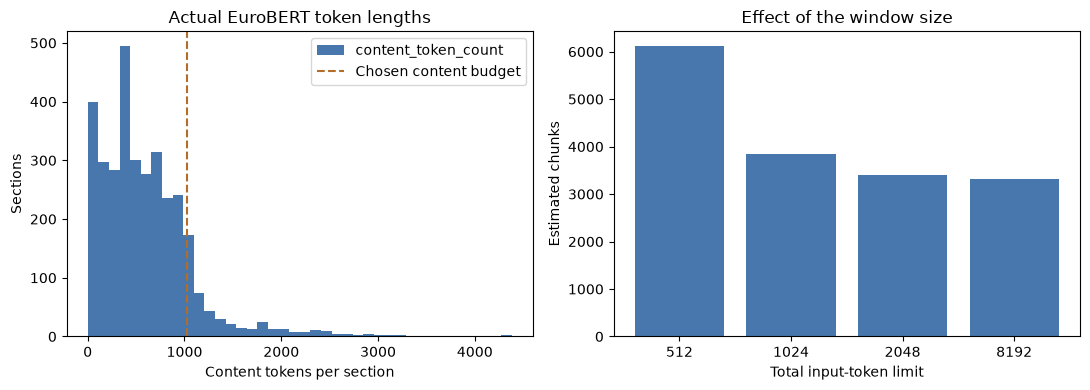

In [5]:
def estimate_windows(token_count, total_limit, overlap):
    capacity = total_limit - SPECIAL_TOKEN_COUNT
    if token_count == 0:
        return 0
    if token_count <= capacity:
        return 1
    return 1 + math.ceil((token_count - capacity) / (capacity - overlap))

policy_rows = []
for limit in sorted(set([512, 1024, 2048, MODEL_LIMIT])):
    if limit > MODEL_LIMIT or limit - SPECIAL_TOKEN_COUNT <= OVERLAP_TOKENS:
        continue
    policy_rows.append({'total_input_limit': limit, 'content_budget': limit - SPECIAL_TOKEN_COUNT,
                        'overlap_tokens': OVERLAP_TOKENS,
                        'sections_needing_multiple_chunks': int((tokenized.content_token_count > limit - SPECIAL_TOKEN_COUNT).sum()),
                        'estimated_chunks': sum(estimate_windows(int(n), limit, OVERLAP_TOKENS) for n in tokenized.content_token_count)})
policy_comparison = pd.DataFrame(policy_rows)
display(policy_comparison)
display(tokenized.groupby('detected_language').content_token_count.agg(['count', 'median', 'max']).round(1))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tokenized.content_token_count.plot.hist(bins=40, ax=axes[0], color='#4777ad')
axes[0].axvline(CONTENT_BUDGET, color='#b56c29', linestyle='--', label='Chosen content budget')
axes[0].set(xlabel='Content tokens per section', ylabel='Sections', title='Actual EuroBERT token lengths')
axes[0].legend()
axes[1].bar(policy_comparison.total_input_limit.astype(str), policy_comparison.estimated_chunks, color='#4777ad')
axes[1].set(xlabel='Total input-token limit', ylabel='Estimated chunks', title='Effect of the window size')
fig.tight_layout()
plt.show()

## 6 Inspect actual tokens manually

The table shows real source spans, token strings, IDs and decoded pieces for English, Dutch and scientific terminology. Visible `Ġ`/`Ċ`-like symbols in token strings represent bytes such as spaces/newlines; decoded pieces and source spans are the readable views. A word split across several tokens is normal. Removing those pieces or negation tokens would change the input.

For the negation examples, compare the original context and decoded token sequence and confirm that the negation remains present. For the technical example, inspect the subword pieces of Nannochloropsis. These are manual inspection examples, not an accuracy metric for the whole collection.

In [6]:
manual_examples = []
for language, pattern, purpose in [
    ('en', r'\b(?:not|without)\b', 'English negation'),
    ('nl', r'\b(?:niet|geen)\b', 'Dutch negation'),
    ('en', r'Nannochloropsis', 'Scientific term'),
]:
    available = tokenized.loc[tokenized.detected_language.eq(language) & tokenized.original_text.str.contains(pattern, case=False, regex=True)].copy()
    if purpose == 'Scientific term':
        preferred = available.loc[available.file_name.str.startswith('025_')]
        if not preferred.empty:
            available = preferred
    else:
        available = available.sort_values('language_score', ascending=False)
    if available.empty:
        print('No matching example:', purpose)
        continue
    record = available.iloc[0]
    match = re.search(pattern, record.original_text, flags=re.I)
    selected_positions = [i for i, (start, end) in enumerate(record.offset_mapping)
                          if end > max(0, match.start() - 35) and start < min(len(record.original_text), match.end() + 60)]
    first, last = selected_positions[0], selected_positions[-1] + 1
    # Expand across shared Unicode offsets so inspection never starts inside a character.
    while first > 0 and record.offset_mapping[first - 1][1] > record.offset_mapping[first][0]:
        first -= 1
    while last < record.content_token_count and record.offset_mapping[last - 1][1] > record.offset_mapping[last][0]:
        last += 1
    fragment_ids = record.content_input_ids[first:last]
    fragment_start = record.offset_mapping[first][0]
    fragment_end = record.offset_mapping[last - 1][1]
    source_fragment = record.original_text[fragment_start:fragment_end]
    decoded_fragment = tokenizer.decode(fragment_ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)
    assert decoded_fragment == source_fragment, 'Inspection fragment did not round-trip exactly.'
    manual_examples.append({'example': purpose, 'file_name': record.file_name,
                            'section_number': int(record.section_number), 'source_fragment': source_fragment,
                            'decoded_fragment': decoded_fragment, 'exact_match': source_fragment == decoded_fragment})
    print('\nEXAMPLE:', purpose, '|', record.file_name, '| section', record.section_number)
    print('Original context:', repr(source_fragment))
    print('Decoded context: ', repr(decoded_fragment))
    table = []
    for i in range(first, min(last, first + 40)):
        start, end = record.offset_mapping[i]
        table.append({'token_position': i, 'token_id': record.content_input_ids[i],
                      'token_string': tokenizer.convert_ids_to_tokens(record.content_input_ids[i]),
                      'original_span': repr(record.original_text[start:end]), 'char_start': start, 'char_end': end})
    display(pd.DataFrame(table))
manual_examples_df = pd.DataFrame(manual_examples)


EXAMPLE: English negation | 035_evaluation-integrated-nurse-led-care-model-ticc-presentation-care4-conference.pdf | section 8
Original context: '                     to trust my team and not to worry\n                                                                                       '
Decoded context:  '                     to trust my team and not to worry\n                                                                                       '


,token_position,token_id,token_string,original_span,char_start,char_end
0,82,3909,ĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠ,' ',680,700
1,83,311,Ġto,' to',700,703
2,84,7095,Ġtrust,' trust',703,709
3,85,856,Ġmy,' my',709,712
4,86,2128,Ġteam,' team',712,717
5,87,323,Ġand,' and',717,721
6,88,539,Ġnot,' not',721,725
7,89,311,Ġto,' to',725,728
8,90,11196,Ġworry,' worry',728,734
9,91,198,Ċ,'\n',734,735



EXAMPLE: Dutch negation | 058_lasten-en-lusten-in-balans.pdf | section 7
Original context: ' onderzoek naar de milieueffecten waren niet beschikbaar ten tijde van het\nschrijven van dit impactrapport'
Decoded context:  ' onderzoek naar de milieueffecten waren niet beschikbaar ten tijde van het\nschrijven van dit impactrapport'


,token_position,token_id,token_string,original_span,char_start,char_end
0,5,38861,Ġonder,' onder',21,27
1,6,82713,zoek,'zoek',27,31
2,7,30948,Ġnaar,' naar',31,36
3,8,409,Ġde,' de',36,39
4,9,7625,Ġmil,' mil',39,43
5,10,648,ie,'ie',43,45
6,11,361,ue,'ue',45,47
7,12,1740,ffect,'ffect',47,52
8,13,268,en,'en',52,54
9,14,44403,Ġwaren,' waren',54,60



EXAMPLE: Scientific term | 025_the-effect-of-drying-cell-disruption-and-storage-on-the-sensory-properties-of-nannochloropsis-sp.pdf | section 1
Original context: ' storage on the sensory properties of\nNannochloropsis sp.\nBert Coleman a,b,*, Christof Van Poucke c, Bavo De Witte'
Decoded context:  ' storage on the sensory properties of\nNannochloropsis sp.\nBert Coleman a,b,*, Christof Van Poucke c, Bavo De Witte'


,token_position,token_id,token_string,original_span,char_start,char_end
0,49,5942,Ġstorage,' storage',372,380
1,50,389,Ġon,' on',380,383
2,51,279,Ġthe,' the',383,387
3,52,49069,Ġsensory,' sensory',387,395
4,53,6012,Ġproperties,' properties',395,406
5,54,315,Ġof,' of',406,409
6,55,198,Ċ,'\n',409,410
7,56,45,N,'N',410,411
8,57,1036,ann,'ann',411,414
9,58,5059,och,'och',414,417


## 7 Create overlapping chunks within each source section

Each chunk contains at most the chosen total input-token budget, including the tokenizer's own special wrapper. Chunks never combine different source sections or documents. Source-token ranges use an exclusive end index, so `[0, 1023)` means content positions 0 through 1022.

The next chunk repeats approximately 128 content tokens from the previous one. Unicode-safe boundaries may increase that overlap slightly. Token windows can still start or end inside an ordinary word or sentence; flags make those cases visible for inspection. More elaborate sentence-aware chunking can be compared later, after this transparent baseline.

`chunk_text` is an exact original substring for inspection. The exported `input_ids` are the model inputs built from the original section's token IDs; use those IDs later rather than assuming separately re-tokenising a substring always gives identical IDs.

In [7]:
def make_chunks(record, total_limit=MAX_INPUT_TOKENS, overlap=OVERLAP_TOKENS):
    ids = record['content_input_ids']
    offsets = record['offset_mapping']
    text = record['original_text']
    count = len(ids)
    capacity = total_limit - SPECIAL_TOKEN_COUNT
    assert 0 < total_limit <= MODEL_LIMIT and 0 <= overlap < capacity
    if count == 0:
        return []
    safe = [0] + [i for i in range(1, count) if offsets[i - 1][1] <= offsets[i][0]] + [count]
    chunks = []
    start = 0
    previous_end = 0
    while start < count:
        target_end = min(start + capacity, count)
        end = safe[bisect_right(safe, target_end) - 1]
        if end <= start:
            raise ValueError('The token budget is too small for a complete Unicode character.')
        char_start = 0 if start == 0 else offsets[start][0]
        char_end = len(text) if end == count else offsets[end][0]
        payload = ids[start:end]
        input_ids = PREFIX_IDS + payload + SUFFIX_IDS
        source_text = text[char_start:char_end]
        chunk_number = len(chunks) + 1
        chunk_id = 'chunk_' + hashlib.sha256(
            f"{record['source_section_id']}:{MODEL_REVISION}:{start}:{end}:{total_limit}:{overlap}".encode()
        ).hexdigest()[:20]
        chunks.append({
            'chunk_id': chunk_id, 'document_id': record['document_id'], 'file_name': record['file_name'],
            'source_section_id': record['source_section_id'], 'section_number': int(record['section_number']),
            'section_label': record['section_label'], 'chunk_number': chunk_number,
            'page_start': int(record['page_start']), 'page_end': int(record['page_end']),
            'detected_language': record['detected_language'], 'language_score': float(record['language_score']),
            'source_token_start': start, 'source_token_end': end,
            'source_char_start': char_start, 'source_char_end': char_end,
            'source_text_sha256': record['source_text_sha256'], 'chunk_text': source_text,
            'content_token_count': len(payload), 'input_token_count': len(input_ids),
            'overlap_with_previous_tokens': max(0, previous_end - start),
            'input_ids': input_ids, 'attention_mask': [1] * len(input_ids),
            'special_tokens_mask': [1] * len(PREFIX_IDS) + [0] * len(payload) + [1] * len(SUFFIX_IDS),
            'starts_mid_word': bool(char_start > 0 and text[char_start - 1].isalnum() and text[char_start].isalnum()),
            'ends_mid_word': bool(char_end < len(text) and text[char_end - 1].isalnum() and text[char_end].isalnum()),
            'decoded_content_matches_source': tokenizer.decode(payload, skip_special_tokens=False,
                                                                clean_up_tokenization_spaces=False) == source_text,
        })
        if end == count:
            break
        previous_end = end
        desired_start = end - overlap
        next_start = safe[bisect_right(safe, desired_start) - 1]
        if next_start <= start:
            next_start = safe[bisect_right(safe, start)]
        assert start < next_start <= end
        start = next_start
    return chunks

chunk_records = []
for record in token_records:
    chunk_records.extend(make_chunks(record))
chunks = pd.DataFrame(chunk_records)
print('Chunks created:', len(chunks))
print('Sections producing multiple chunks:', int((chunks.groupby('source_section_id').size() > 1).sum()))
print('Largest complete model input:', int(chunks.input_token_count.max()), 'tokens')
print('Repeated overlap tokens:', int(chunks.overlap_with_previous_tokens.sum()))
print('Chunks starting inside a word:', int(chunks.starts_mid_word.sum()))
print('Chunks ending inside a word:', int(chunks.ends_mid_word.sum()))
print('Chunks with exact source/decoded content:', int(chunks.decoded_content_matches_source.sum()), '/', len(chunks))
display(chunks.input_token_count.describe().rename('input_tokens_per_chunk').to_frame())

Chunks created: 3843
Sections producing multiple chunks: 412
Largest complete model input: 1024 tokens
Repeated overlap tokens: 66049
Chunks starting inside a word: 102
Chunks ending inside a word: 109
Chunks with exact source/decoded content: 3843 / 3843


,input_tokens_per_chunk
count,3843.000000
mean,536.052043
std,326.635434
min,2.000000
25%,253.500000
50%,500.000000
75%,830.000000
max,1024.000000


## 8 Validate every token and source substring

Remove only the automatically added special wrapper and discard the known overlap when reconstructing a section's token sequence. Compare the reconstructed IDs with the full original section IDs. Also reconstruct original text using character spans, checking for gaps and mismatched substrings.

This verifies that chunking has not silently discarded the end of long sections. It does not establish correct PDF reading order, accurate language labels or keyword quality. No padding is stored; future batching may add padding and update attention masks then.

In [8]:
def validate_all_chunks(token_rows, chunk_frame):
    groups = {key: group.sort_values('chunk_number') for key, group in chunk_frame.groupby('source_section_id')}
    assert not chunk_frame.chunk_id.duplicated().any()
    assert chunk_frame.input_token_count.le(MAX_INPUT_TOKENS).all()
    assert chunk_frame.input_token_count.le(MODEL_LIMIT).all()
    assert set(groups) == {record['source_section_id'] for record in token_rows if record['content_token_count'] > 0}
    checked = 0
    for record in token_rows:
        ids, text = record['content_input_ids'], record['original_text']
        if not ids:
            continue
        recovered_ids, recovered_text = [], []
        token_cursor = char_cursor = 0
        previous_end = 0
        for row in groups[record['source_section_id']].to_dict(orient='records'):
            start, end = row['source_token_start'], row['source_token_end']
            assert start <= token_cursor < end <= len(ids), 'Token gap or redundant window.'
            payload = [value for value, special in zip(row['input_ids'], row['special_tokens_mask']) if not special]
            assert payload == ids[start:end]
            assert row['input_ids'] == PREFIX_IDS + payload + SUFFIX_IDS
            assert len(row['attention_mask']) == len(row['input_ids']) == len(row['special_tokens_mask'])
            assert all(value == 1 for value in row['attention_mask'])
            assert all(0 <= value < model_config['vocab_size'] for value in row['input_ids'])
            assert row['overlap_with_previous_tokens'] == max(0, previous_end - start)
            assert row['document_id'] == record['document_id'] and row['section_number'] == record['section_number']
            a, b = row['source_char_start'], row['source_char_end']
            assert 0 <= a <= char_cursor <= b <= len(text), 'Character gap.'
            assert row['chunk_text'] == text[a:b]
            recovered_ids.extend(payload[token_cursor - start:])
            recovered_text.append(row['chunk_text'][char_cursor - a:])
            token_cursor, char_cursor, previous_end = end, b, end
        assert recovered_ids == ids, 'Source token IDs were lost or changed.'
        assert ''.join(recovered_text) == text, 'Original source characters were lost or changed.'
        assert token_cursor == len(ids) and char_cursor == len(text)
        checked += 1
    return checked

validated_sections = validate_all_chunks(token_records, chunks)
print('Validated complete token and text coverage for', validated_sections, 'sections.')
print('Unknown-token count:', int(tokenized.unknown_token_count.sum()))

# Edge cases are checked inside the notebook, including byte-split Unicode.
for sample_text in ['Dit onderzoek laat geen schade zien. µg/L ± 0.14 🙂 👨‍👩‍👧 ' * 8, '\n\t', '']:
    encoded = tokenizer(sample_text, add_special_tokens=False, return_offsets_mapping=True)
    test_record = dict(token_records[0])
    test_record.update(original_text=sample_text, content_input_ids=encoded['input_ids'],
                       offset_mapping=encoded['offset_mapping'], content_token_count=len(encoded['input_ids']))
    test_chunks = make_chunks(test_record, total_limit=24, overlap=4)
    recovered = []
    cursor = 0
    for chunk in test_chunks:
        payload = [value for value, special in zip(chunk['input_ids'], chunk['special_tokens_mask']) if not special]
        recovered.extend(payload[cursor - chunk['source_token_start']:])
        cursor = chunk['source_token_end']
        assert chunk['input_token_count'] <= 24
        assert chunk['decoded_content_matches_source']
    assert recovered == encoded['input_ids']
print('Unicode, negation, whitespace and empty-input regression checks passed.')

Validated complete token and text coverage for 3327 sections.
Unknown-token count: 0
Unicode, negation, whitespace and empty-input regression checks passed.


## 9 Inspect a real chunk boundary and prepare a small review sample

Display the first two chunks of the longest source section. The range table and source snippets show what is repeated and where the second window continues. Verify that the overlap supplies context, the text remains legible and no replacement character was introduced by splitting Unicode.

The review table selects long, short, English, Dutch and other/uncertain cases, then fills a reproducible 12-section sample. Automatic checks are populated; human review fields remain blank until reviewed. Review the source and decoded text, technical symbols, negations and boundaries. Upstream extraction artefacts are expected to remain visible because this notebook preserves its input.

In [9]:
longest = tokenized.sort_values('content_token_count', ascending=False).iloc[0]
boundary_example = chunks.loc[chunks.source_section_id.eq(longest.source_section_id)].sort_values('chunk_number').head(2)
display(boundary_example[['file_name', 'section_number', 'chunk_number', 'source_token_start', 'source_token_end',
                          'input_token_count', 'overlap_with_previous_tokens', 'source_char_start', 'source_char_end']])
if len(boundary_example) == 2:
    first, second = boundary_example.iloc[0], boundary_example.iloc[1]
    print('First chunk ending:', repr(first.chunk_text[-240:]))
    print('Second chunk beginning:', repr(second.chunk_text[:240]))
    overlap_ids = longest.content_input_ids[int(second.source_token_start):int(first.source_token_end)]
    print('Repeated context:', repr(tokenizer.decode(overlap_ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)))

selected = []
for frame in [tokenized.sort_values('content_token_count', ascending=False),
              tokenized.loc[tokenized.content_token_count.gt(0)].sort_values('content_token_count'),
              tokenized.loc[tokenized.detected_language.eq('en')],
              tokenized.loc[tokenized.detected_language.eq('nl')],
              tokenized.loc[~tokenized.detected_language.isin(['en', 'nl'])]]:
    if not frame.empty:
        selected.append(frame.index[0])
selected = list(dict.fromkeys(selected))
remaining = tokenized.drop(index=selected).sample(frac=1, random_state=RANDOM_SEED)
selected += remaining.index[:max(0, 12 - len(selected))].tolist()
review_sample = tokenized.loc[selected, ['source_section_id', 'document_id', 'file_name', 'section_number',
                                       'page_start', 'page_end', 'section_label', 'detected_language',
                                       'language_score', 'content_token_count', 'roundtrip_exact']].copy()
review_sample['chunk_count'] = review_sample.source_section_id.map(chunks.groupby('source_section_id').size()).fillna(0).astype(int)
review_sample['human_review_status'] = ''
review_sample['review_notes'] = ''
display(review_sample[['file_name', 'section_number', 'detected_language', 'content_token_count', 'chunk_count', 'roundtrip_exact']])

,file_name,section_number,chunk_number,source_token_start,source_token_end,input_token_count,overlap_with_previous_tokens,source_char_start,source_char_end
1079,025_the-effect-of-drying-cell-disruption-and-s...,14,1,0,1023,1024,0,0,3518
1080,025_the-effect-of-drying-cell-disruption-and-s...,14,2,895,1918,1024,128,3060,6332


First chunk ending: '  taste, free amino acid composition, and volatile compounds of brown seaweeds,\n      algal.2017.06.013.                                                                                         J. Appl. Phycol. 31 (2) (2019) 1213–1232, https'
Second chunk beginning: ' the lipolytic stability during       [41] O.G. Mouritsen, L. Duelund, M.A. Petersen, A.L. Hartmann, M.B. Frøst, Umami\n     wet storage, Algal Res. 25 (2017) 516–524, https://doi.org/10.1016/j.                           taste, free amino ac'
Repeated context: ' the lipolytic stability during       [41] O.G. Mouritsen, L. Duelund, M.A. Petersen, A.L. Hartmann, M.B. Frøst, Umami\n     wet storage, Algal Res. 25 (2017) 516–524, https://doi.org/10.1016/j.                           taste, free amino acid composition, and volatile compounds of brown seaweeds,\n      algal.2017.06.013.                                                                                         J. Appl. Phycol. 31 (2) (2019) 1213–

,file_name,section_number,detected_language,content_token_count,chunk_count,roundtrip_exact
925,025_the-effect-of-drying-cell-disruption-and-s...,14,en,4382,5,True
440,061_leven-in-zeeland.pdf,6,uncertain,1,1,True
0,071_overflow-tests-belgian-levees-annexes.pdf,1,en,85,1,True
183,013_grip-op-teksten-grip-op-kennis.pdf,1,nl,1285,2,True
4,071_overflow-tests-belgian-levees-annexes.pdf,5,uncertain,21,1,True
1062,062_leven-in-zeeland-2021.pdf,101,nl,735,1,True
816,017_integrating-text-structure-instruction-in-...,15,en,505,1,True
2663,057_kijk-op-later-pilot.pdf,40,nl,521,1,True
813,017_integrating-text-structure-instruction-in-...,12,en,64,1,True
866,048_eindrapportage-lokaal-preventieakkoord-gem...,36,nl,546,1,True


## 10 Save the handover outputs and verify the saved chunks

The two principal outputs are:

| File | Use |
|---|---|
| `tokenized_sections.jsonl` | Original section text, complete content IDs and character offsets; source record for checking. |
| `chunks.jsonl` | Model-ready input IDs, attention masks, special-token masks and source ranges; handover to the later embedding step. |

`summary.csv` records the main counts, `manual_review.csv` records the small human-review sample and `run_config.json` records checkpoint revision, asset/input hashes and settings. Review notes are preserved when the input hashes and chunk settings match; a changed run writes a new review template instead of silently mixing configurations.

Do not count overlapping tokens as additional independent evidence, and group all chunks from the same document when later splitting train/test data. Notebook 05's exports remain unchanged.

In [10]:
source_hashes = input_hashes_before
run_config = {
    'model_id': MODEL_ID, 'model_revision': MODEL_REVISION, 'model_limit': MODEL_LIMIT,
    'max_input_tokens': MAX_INPUT_TOKENS, 'special_token_count': SPECIAL_TOKEN_COUNT,
    'content_budget': CONTENT_BUDGET, 'overlap_tokens': OVERLAP_TOKENS,
    'prefix_ids': PREFIX_IDS, 'suffix_ids': SUFFIX_IDS, 'random_seed': RANDOM_SEED,
    'transformers_version': transformers.__version__, 'tokenizers_version': tokenizers.__version__,
    'python_version': platform.python_version(), 'input_sha256': source_hashes,
    'tokenizer_asset_sha256': {name: hashlib.sha256((TOKENIZER_DIR / name).read_bytes()).hexdigest() for name in asset_names},
    'embeddings_computed': False, 'tokenization_seconds_this_run': tokenization_seconds,
}
summary_rows = [
    {'measure': 'Source documents', 'value': joined.document_id.nunique()},
    {'measure': 'Source sections', 'value': len(tokenized)},
    {'measure': 'Original characters', 'value': int(tokenized.original_text.str.len().sum())},
    {'measure': 'Content tokens', 'value': int(tokenized.content_token_count.sum())},
    {'measure': 'Exact section round trips', 'value': int(tokenized.roundtrip_exact.sum())},
    {'measure': 'Chosen input-token limit', 'value': MAX_INPUT_TOKENS},
    {'measure': 'Sections needing multiple chunks', 'value': int((chunks.groupby('source_section_id').size() > 1).sum())},
    {'measure': 'Chunks', 'value': len(chunks)},
    {'measure': 'Largest model input', 'value': int(chunks.input_token_count.max())},
    {'measure': 'Repeated overlap tokens', 'value': int(chunks.overlap_with_previous_tokens.sum())},
    {'measure': 'Unknown tokens', 'value': int(tokenized.unknown_token_count.sum())},
]
summary = pd.DataFrame(summary_rows)
tokenized.to_json(OUTPUT_DIR / 'tokenized_sections.jsonl', orient='records', lines=True, force_ascii=False)
chunks.to_json(OUTPUT_DIR / 'chunks.jsonl', orient='records', lines=True, force_ascii=False)
summary.to_csv(OUTPUT_DIR / 'summary.csv', index=False, encoding='utf-8-sig')
old_config_path = OUTPUT_DIR / 'run_config.json'
old_config = json.loads(old_config_path.read_text()) if old_config_path.exists() else None
comparison_keys = ['model_revision', 'max_input_tokens', 'overlap_tokens', 'input_sha256']
same_review_run = old_config is not None and all(old_config.get(key) == run_config[key] for key in comparison_keys)
review_path = OUTPUT_DIR / 'manual_review.csv'
if not review_path.exists():
    review_sample.to_csv(review_path, index=False, encoding='utf-8-sig')
elif same_review_run:
    print('Preserved existing manual-review notes for the same run.')
else:
    run_tag = hashlib.sha256(json.dumps({key: run_config[key] for key in comparison_keys}, sort_keys=True).encode()).hexdigest()[:10]
    review_path = OUTPUT_DIR / f'manual_review_{run_tag}.csv'
    if not review_path.exists():
        review_sample.to_csv(review_path, index=False, encoding='utf-8-sig')
    print('Separate review template for changed settings:', review_path.name)
old_config_path.write_text(json.dumps(run_config, indent=2))
saved_chunks = pd.read_json(OUTPUT_DIR / 'chunks.jsonl', lines=True)
assert validate_all_chunks(token_records, saved_chunks) == validated_sections
for path in [sections_path, languages_path]:
    assert hashlib.sha256(path.read_bytes()).hexdigest() == source_hashes[path.name]
print('Saved chunk IDs, token coverage and original text coverage verified.')
display(summary)

Preserved existing manual-review notes for the same run.
Saved chunk IDs, token coverage and original text coverage verified.


,measure,value
0,Source documents,92
1,Source sections,3327
2,Original characters,9367556
3,Content tokens,1990156
4,Exact section round trips,3327
5,Chosen input-token limit,1024
6,Sections needing multiple chunks,412
7,Chunks,3843
8,Largest model input,1024
9,Repeated overlap tokens,66049


## 11 Findings and scope of the manual checks

Read the populated findings below alongside the token and boundary examples. The English and Dutch negation examples and the scientific-term example were selected for direct source/decoded comparison. A split word is expected subword behaviour; it is not missing text. The source/decoded equality checks establish preservation, not semantic understanding or keyword quality.

The 12-section human-review template is additional work; its blank fields do not represent completed review. Existing mixed-column passages, broken words and questionable section labels belong to the upstream extraction/segmentation stage and remain in these inputs.

**Current result:** the longest section has 4,382 content tokens, below EuroBERT's 8,191-token content budget after its one added special token. None of these sections requires splitting at the architectural limit. The 1,024-token setting demonstrates a smaller, configurable working-window policy; setting `MAX_INPUT_TOKENS = MODEL_LIMIT` will keep each current section in a single chunk.

**Reviewed token examples:** English `not` and Dutch `niet` remain present in the decoded contexts. The scientific term Nannochloropsis splits into `N`, `ann`, `och`, `lor`, `opsis` and decodes back correctly. The inspected longest-section boundary retains the repeated source context. It also retains the original interleaved references, demonstrating that tokenisation preserves upstream layout artefacts rather than repairing them.


In [11]:
findings = pd.DataFrame([
    {'finding': 'Input wording retained', 'evidence': f'{len(tokenized)} original sections; {int(tokenized.original_text.str.len().sum()):,} characters retained.'},
    {'finding': 'Real model tokenisation', 'evidence': f'{int(tokenized.content_token_count.sum()):,} content tokens using {MODEL_ID} at pinned revision {MODEL_REVISION[:8]}.'},
    {'finding': 'Full section round-trip check', 'evidence': f'{int(tokenized.roundtrip_exact.sum())}/{len(tokenized)} exact source/decoded matches; inspect any mismatches before claiming lossless tokenisation.'},
    {'finding': 'Negation inspection examples', 'evidence': 'English and Dutch source fragments and decoded fragments are displayed above; the negation is retained rather than stop-word filtered.'},
    {'finding': 'Technical terms split into subwords', 'evidence': 'The actual Nannochloropsis token strings/IDs are displayed above; decoded text reconstructs the source fragment.'},
    {'finding': 'Architecture-limit finding', 'evidence': f'The longest current section is {int(tokenized.content_token_count.max()):,} content tokens. {(tokenized.content_token_count > MODEL_LIMIT - SPECIAL_TOKEN_COUNT).sum()} sections require splitting to fit the {MODEL_LIMIT}-token checkpoint limit. Smaller working chunks are optional.'},
    {'finding': 'Working window is configurable', 'evidence': f'{MAX_INPUT_TOKENS} total tokens chosen for preparation; checkpoint supports {MODEL_LIMIT}; no quality optimum has been established.'},
    {'finding': 'Complete chunk coverage', 'evidence': f'{validated_sections} sections validated after overlap removal and character-span reconstruction; {len(chunks)} chunks exported.'},
    {'finding': 'Boundary trade-off', 'evidence': f'{int(chunks.starts_mid_word.sum())} chunk starts and {int(chunks.ends_mid_word.sum())} chunk ends fall inside words. Unicode-safe token windows preserve IDs, but sentence/word-aware alternatives can be compared later.'},
    {'finding': 'Source extraction issues remain', 'evidence': 'This stage keeps the original Notebook 05 text and section/language labels; tokenisation does not correct mixed PDF columns.'},
    {'finding': 'Next stage', 'evidence': 'Inspect the review sample, then use chunks.jsonl for a separate embedding experiment. No embeddings or model weights were loaded here.'},
])
with pd.option_context('display.max_colwidth', 180):
    display(findings)

,finding,evidence
0,Input wording retained,"3327 original sections; 9,367,556 characters retained."
1,Real model tokenisation,"1,990,156 content tokens using EuroBERT/EuroBERT-210m at pinned revision 39b51e15."
2,Full section round-trip check,3327/3327 exact source/decoded matches; inspect any mismatches before claiming lossless tokenisation.
3,Negation inspection examples,English and Dutch source fragments and decoded fragments are displayed above; the negation is retained rather than stop-word filtered.
4,Technical terms split into subwords,The actual Nannochloropsis token strings/IDs are displayed above; decoded text reconstructs the source fragment.
5,Architecture-limit finding,"The longest current section is 4,382 content tokens. 0 sections require splitting to fit the 8192-token checkpoint limit. Smaller working chunks are optional."
6,Working window is configurable,1024 total tokens chosen for preparation; checkpoint supports 8192; no quality optimum has been established.
7,Complete chunk coverage,3327 sections validated after overlap removal and character-span reconstruction; 3843 chunks exported.
8,Boundary trade-off,"102 chunk starts and 109 chunk ends fall inside words. Unicode-safe token windows preserve IDs, but sentence/word-aware alternatives can be compared later."
9,Source extraction issues remain,This stage keeps the original Notebook 05 text and section/language labels; tokenisation does not correct mixed PDF columns.


## Sources

- [EuroBERT-210m model card](https://huggingface.co/EuroBERT/EuroBERT-210m)
- [Pinned model configuration](https://huggingface.co/EuroBERT/EuroBERT-210m/blob/39b51e15dd1f1a06f58b5cbf6a8a188cec60bd0e/config.json)
- [Hugging Face tokenizer documentation](https://huggingface.co/docs/transformers/main_classes/tokenizer)

All collection statistics and preservation checks are computed from the local Notebook 05 exports. Tokenizer assets are downloaded, while document text stays local. Actual tokenisation and chunking results are preparation evidence; they are not model evaluation scores.